# 02 · A base canônica (`desafio1_bracis.db`)

**Desafio 1 — BRACIS 2026 / Jusbrasil**

93 MB de SQLite com 1.016 registros. É a *cobertura congelada*: o universo que
decide se uma citação é `real` ou `inventada`. Se um acórdão existe no mundo mas
não está aqui, para efeito do desafio ele não existe.

Este notebook mapeia o que há dentro, e termina na pergunta que mais importa para o
pipeline: **onde, dentro de um documento, mora o número que o identifica** — o sinal
que separa o registro de quem apenas o cita.

In [1]:
import sys, re, collections
from pathlib import Path

# permite importar eda_utils tanto rodando de analise/, src/ ou da raiz
for base in [Path.cwd(), *Path.cwd().parents]:
    if (base / "src" / "eda_utils.py").exists():
        sys.path.insert(0, str(base / "src"))
        break

import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as u

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("raiz do projeto:", u.raiz_projeto())

raiz do projeto: /work


In [2]:
con = u.conectar_base()   # abre com immutable=1; ver observação abaixo

print("tabelas:", [r[0] for r in con.execute(
    "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")])
print()
for cid, nome, tipo, notnull, default, pk in con.execute("PRAGMA table_info(documentos)"):
    print(f"  {nome:<14} {tipo:<8} {'PK' if pk else ''}{' NOT NULL' if notnull else ''}")

tabelas: ['documentos', 'documentos_fts', 'documentos_fts_config', 'documentos_fts_data', 'documentos_fts_docsize', 'documentos_fts_idx']

  documento_id   TEXT     PK
  id             INTEGER   NOT NULL
  tribunal       TEXT     
  ano            INTEGER  
  relator        TEXT     
  natureza       TEXT      NOT NULL
  tipo           TEXT      NOT NULL
  texto          TEXT      NOT NULL
  texto_len      INTEGER   NOT NULL


> **Sobre abrir o banco.** Se o repositório estiver num compartilhamento de rede
> (WSL/UNC, como aqui), `sqlite3.connect(caminho)` falha com *"database is locked"*:
> o SQLite não consegue criar o arquivo de lock. `u.conectar_base()` contorna isso
> abrindo em modo `immutable=1`, que declara o arquivo imutável e dispensa lock.
> É o modo correto para esta base de qualquer forma — ela é um snapshot, ninguém
> escreve nela.

## 1. Os dois eixos de tipagem

`tipo` é o enum do contrato de submissão e tem dois valores. `natureza` existe
porque `tipo` sozinho não separa acórdão de súmula — os dois são `jurisprudencia`.

In [3]:
tipos = pd.read_sql_query(
    "SELECT tipo, natureza, COUNT(*) AS registros FROM documentos GROUP BY 1,2 ORDER BY 3 DESC", con)
print(tipos.to_string(index=False))

trib = pd.read_sql_query(
    "SELECT COALESCE(tribunal,'(lei)') AS tribunal, natureza, COUNT(*) AS n "
    "FROM documentos GROUP BY 1,2", con)
pd.pivot_table(trib, index="tribunal", columns="natureza", values="n", fill_value=0)

          tipo    natureza  registros
jurisprudencia     acordao        998
           lei dispositivo         13
jurisprudencia      sumula          5


natureza,acordao,dispositivo,sumula
tribunal,,,
(lei),0.0,13.0,0.0
STF,200.0,0.0,1.0
STJ,199.0,0.0,3.0
STM,200.0,0.0,0.0
TSE,199.0,0.0,0.0
TST,200.0,0.0,1.0


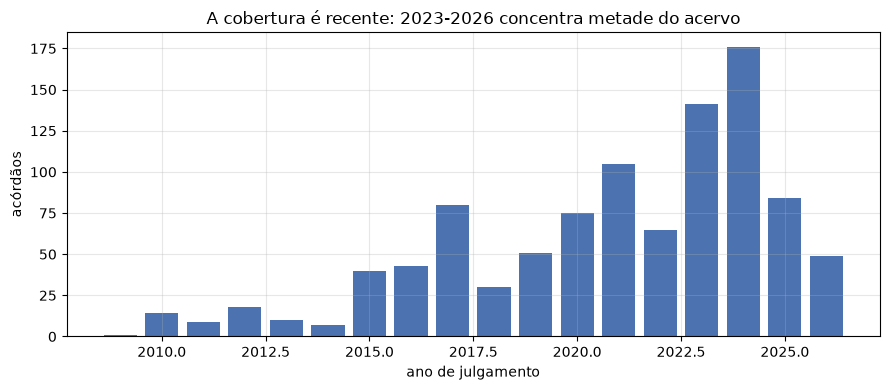

ano  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
n       1    14     9    18    10     7    40    43    80    30    51    75   105    65   141   176    84    49


In [4]:
anos = pd.read_sql_query(
    "SELECT ano, COUNT(*) AS n FROM documentos WHERE ano IS NOT NULL GROUP BY 1 ORDER BY 1", con)
plt.bar(anos.ano, anos.n, color="#4C72B0")
plt.xlabel("ano de julgamento"); plt.ylabel("acórdãos")
plt.title("A cobertura é recente: 2023-2026 concentra metade do acervo")
plt.tight_layout(); plt.show()
print(anos.set_index("ano").T.to_string())

O acervo vai de 2009 a 2026, mas é fortemente recente — 2024 sozinho tem 176
acórdãos. Isso tem consequência direta: uma citação `incompleta` do tipo
"acórdão do STF de 2024, relatado pelo Ministro Fulano" cai justamente na faixa
mais densa da base, o que garante muitos candidatos e nenhum critério de desempate.
O desafio não escolheu esses anos por acaso.

## 2. Volume de texto e relatores

count      1016.0
mean      66861.0
std       26680.0
min         210.0
25%       48073.0
50%       68006.0
75%       85965.0
max      149907.0

texto total: 67.9 milhões de caracteres
texto_len bate com length(texto)? True


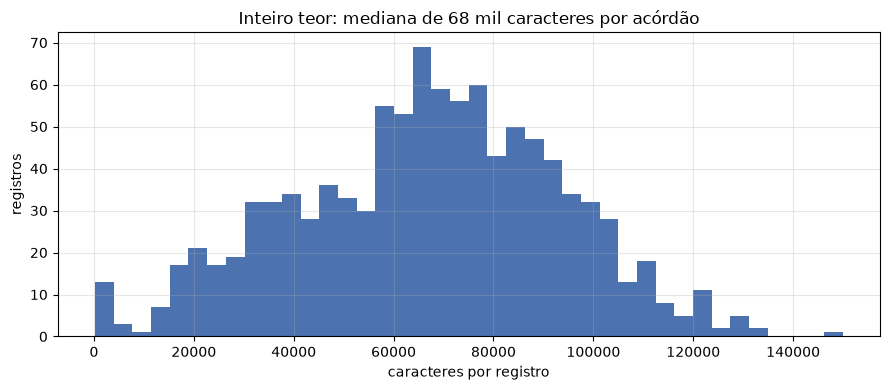

In [5]:
lens = pd.read_sql_query("SELECT texto_len FROM documentos", con)["texto_len"]
print(lens.describe().round(0).to_string())
print(f"\ntexto total: {lens.sum()/1e6:.1f} milhões de caracteres")
print("texto_len bate com length(texto)?",
      con.execute("SELECT COUNT(*) FROM documentos WHERE texto_len <> length(texto)").fetchone()[0] == 0)

plt.hist(lens, bins=40, color="#4C72B0")
plt.xlabel("caracteres por registro"); plt.ylabel("registros")
plt.title("Inteiro teor: mediana de 68 mil caracteres por acórdão")
plt.tight_layout(); plt.show()

In [6]:
rel = pd.read_sql_query(
    "SELECT relator, tribunal, COUNT(*) AS acordaos FROM documentos "
    "WHERE relator IS NOT NULL GROUP BY 1,2 ORDER BY 3 DESC", con)
print("relatores distintos:", rel.relator.nunique())
print(rel.groupby("tribunal").relator.nunique().to_string())
rel.head(12)

relatores distintos: 159
tribunal
STF    25
STJ    50
STM    22
TSE    41
TST    33


,relator,tribunal,acordaos
0,Flávio Dino,STF,45
1,Douglas Alencar Rodrigues,TST,44
2,Assusete Magalhães,STJ,41
3,Min. Sergio Silveira Banhos,TSE,37
4,Marco Antonio,STM,36
5,Edson Fachin,STF,34
6,José Roberto Freire Pimenta,TST,28
7,ARTUR VIDIGAL DE OLIVEIRA,STM,20
8,CLÁUDIO PORTUGAL DE VIVEIROS,STM,18
9,Herman Benjamin,STJ,18


159 relatores para 998 acórdãos: uma média de seis por relator, mas a cauda é
pesada — Flávio Dino sozinho responde por 45. Combinar relator + ano + tribunal
tipicamente devolve entre 4 e 18 candidatos, nunca um. É exatamente por isso que a
classe `incompleta` do desafio inclui referências "buscáveis, porém ambíguas".

## 3. Duplicatas

A documentação avisa que há duplicatas remanescentes do acervo. Vale medir: elas
não afetam a resolução (nenhuma citação aponta para elas), mas inflam a contagem de
candidatos de quem busca por conteúdo em vez de por identificador.

In [7]:
dup = pd.read_sql_query(
    "SELECT COUNT(*) AS grupos_identicos FROM (SELECT texto FROM documentos GROUP BY texto HAVING COUNT(*) > 1)", con)
excedentes = con.execute("SELECT COUNT(*) - COUNT(DISTINCT texto) FROM documentos").fetchone()[0]
print(dup.to_string(index=False))
print("registros excedentes (mesmo texto, id diferente):", excedentes)
print("ids duplicados na coluna id:",
      con.execute("SELECT COUNT(*) - COUNT(DISTINCT id) FROM documentos").fetchone()[0])

 grupos_identicos
               35
registros excedentes (mesmo texto, id diferente): 38
ids duplicados na coluna id: 0


## 4. Os 18 registros que não são acórdão

Súmulas e dispositivos de lei existem como registro próprio porque são **alvo** de
resolução. Buscar "Súmula 83 do STJ" no texto dos acórdãos devolve dezenas de
documentos que a mencionam — e nenhum deles é a súmula.

In [8]:
outros = pd.read_sql_query(
    "SELECT natureza, documento_id, id, COALESCE(tribunal,'-') AS tribunal, "
    "       substr(replace(replace(texto, char(10), ' '), char(13), ' '), 1, 92) AS inicio_do_texto "
    "FROM documentos WHERE natureza IN ('sumula','dispositivo') ORDER BY natureza DESC, id", con)
outros

,natureza,documento_id,id,tribunal,inicio_do_texto
0,sumula,1289710642,1289710642,STJ,DIREITO PROCESSUAL CIVIL - RECURSO ESPECIAL Não se conhece do recurso especial pela di...
1,sumula,1289710776,1289710776,STJ,DIREITO PROCESSUAL CIVIL - RECURSO ESPECIAL Inadmissível recurso especial quanto à que...
2,sumula,1289711022,1289711022,STJ,DIREITO PENAL - APLICAÇÃO DA PENA O aumento na terceira fase de aplicação da pena no c...
3,sumula,1289712966,1289712966,STF,"PROCESSUAL CIVIL Viola a cláusula de reserva de plenário ( CF, artigo 97) a decisão de..."
4,sumula,1431369957,1431369957,TST,CONTRATO DE PRESTAÇÃO DE SERVIÇOS. LEGALIDADE. I - A contratação de trabalhadores por ...
5,dispositivo,10577194,10577194,-,"Art. 276. As decisões dos Tribunais Regionais são terminativas, salvo os casos seguint..."
6,dispositivo,10590194,10590194,-,"Art. 290. Receber, preparar, produzir, vender, fornecer, ainda que gratuitamente, ter ..."
7,dispositivo,10606184,10606184,-,"Art. 14. O fornecedor de serviços responde, independentemente da existência de culpa, ..."
8,dispositivo,10626510,10626510,-,"Art. 93. Lei complementar, de iniciativa do Supremo Tribunal Federal, disporá sobre o ..."
9,dispositivo,10637358,10637358,-,Art. 896 - Cabe Recurso de Revista para Turma do Tribunal Superior do Trabalho das dec...


Repare no que **não** está nesses textos: o número da súmula. O registro da Súmula
331 do TST começa em "CONTRATO DE PRESTAÇÃO DE SERVIÇOS. LEGALIDADE." — em nenhum
lugar ele diz "331". Consequência prática, medida no notebook 04: **súmula não se
resolve por busca numérica**. Ela precisa de um resolvedor dedicado, com um
mapeamento manual de 5 entradas. Jogar uma citação de súmula no resolvedor
numérico é a principal fonte de alucinação carimbada como verificada.

## 5. O índice FTS e a armadilha da tokenização

`documentos_fts` é uma tabela FTS5 *external content* — não duplica o texto, aponta
para `documentos` pelo `rowid`. O tokenizador é o `unicode61`, que quebra em
qualquer caractere não alfanumérico.

In [9]:
def match(termo):
    return con.execute("SELECT COUNT(*) FROM documentos_fts WHERE documentos_fts MATCH ?",
                       (termo,)).fetchone()[0]

for termo in ['"1.741.784"', '"1 741 784"', '1741784', '"1741784"', '"0600216-46.2020.6.14.0022"']:
    print(f"  MATCH {termo:<30} -> {match(termo):>4} resultado(s)")

  MATCH "1.741.784"                    ->    1 resultado(s)
  MATCH "1 741 784"                    ->    1 resultado(s)
  MATCH 1741784                        ->    0 resultado(s)
  MATCH "1741784"                      ->    0 resultado(s)
  MATCH "0600216-46.2020.6.14.0022"    ->    1 resultado(s)


`1.741.784` é indexado como três tokens (`1`, `741`, `784`); a busca por frase
reproduz essa sequência e funciona. `1741784` sem separador é um token único que
não existe no índice — zero resultados. Como o nível 2 entrega números sem
pontuação com frequência, **reagrupar os dígitos de três em três antes de consultar
não é otimização, é requisito**. `u.agrupar_milhares()` faz isso.

## 6. Onde mora o identificador

Esta é a seção decisiva. O FTS devolve *qualquer* documento que mencione o número,
e acórdãos citam uns aos outros o tempo todo. O sinal que separa o registro de quem
apenas o cita é a **posição** do número no texto. A documentação sugere um limiar de
posição; vamos medir se um limiar único serve.

In [10]:
CNJ = re.compile(r"\d{1,7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{4}")
linhas = []
for tribunal, texto in con.execute("SELECT tribunal, texto FROM documentos WHERE natureza='acordao'"):
    m = CNJ.search(texto)
    linhas.append({"tribunal": tribunal, "offset": m.start() if m else None})
pos = pd.DataFrame(linhas)

resumo = pos.dropna().groupby("tribunal")["offset"].describe(percentiles=[.5, .9])
print(resumo[["count", "min", "50%", "90%", "max"]].round(0).to_string())
print("\nacórdãos sem número CNJ no texto, por tribunal:")
print(pos[pos.offset.isna()].groupby("tribunal").size().to_string())

          count    min     50%      90%      max
tribunal                                        
STF       164.0  299.0  4208.0  26217.0  57900.0
STJ        72.0  737.0  7656.0  46374.0  83388.0
STM       200.0   41.0    99.0    111.0   2941.0
TSE       198.0   19.0    87.0   2869.0  72627.0
TST       200.0   88.0  1836.0   6520.0  12547.0

acórdãos sem número CNJ no texto, por tribunal:
tribunal
STF     36
STJ    127
TSE      1


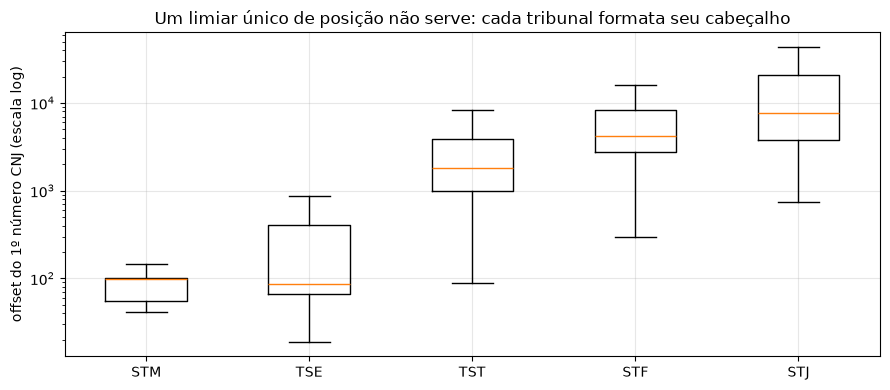

In [11]:
ordem = ["STM", "TSE", "TST", "STF", "STJ"]
dados = [pos.loc[pos.tribunal == t, "offset"].dropna() for t in ordem]
plt.boxplot(dados, showfliers=False)
plt.xticks(range(1, len(ordem) + 1), ordem)
plt.yscale("log"); plt.ylabel("offset do 1º número CNJ (escala log)")
plt.title("Um limiar único de posição não serve: cada tribunal formata seu cabeçalho")
plt.tight_layout(); plt.show()

In [12]:
# O TST não põe o número no topo: ele aparece na fórmula "Vistos, relatados..."
tst = con.execute("SELECT texto FROM documentos WHERE documento_id='doc_0612'").fetchone()[0]
p = tst.find("173000-49.2008.5.15.0024")
print("offset do número no próprio acórdão do TST:", p)
print("contexto:", re.sub(r"\s+", " ", tst[max(0, p-95):p+30]))
print()
print("cabeçalho do mesmo documento:", re.sub(r"\s+", " ", tst[:95]))

offset do número no próprio acórdão do TST: 1017
contexto: hece. Vistos, relatados e discutidos estes autos de Embargos em Recurso de Revista nº TST-E-RR-173000-49.2008.5.15.0024, em q

cabeçalho do mesmo documento: A C Ó R D Ã O SDI-1 CMB/cm RECURSO DE EMBARGOS EM RECURSO DE REVISTA REGIDO PELA LEI Nº 13.015/


## Impressões

**A base é 90% palheiro.** Adiantando um número do notebook 04: só 95 dos 1.016
registros são alvo de alguma citação do gabarito — 9,4%. Os outros 921 existem para
gerar candidatos falsos no FTS. Isso muda a prioridade de engenharia: o problema não
é *encontrar* o registro, é *descartar* os 900 que mencionam o mesmo número.

**O limiar único de posição é uma armadilha.** A documentação sugere filtrar por
posição e usa exemplos com offset < 300. O boxplot mostra por que isso falha: STM e
TSE põem o número CNJ no offset ~90, mas o TST tem mediana em 1.836 — ele abre com
`A C Ó R D Ã O SbDI-1 GMJRP/...` e só nomeia o processo na fórmula "Vistos, relatados
e discutidos estes autos de ...", perto do caractere 1.000. Um limiar de 300 descarta
todos os acórdãos do TST; um limiar de 2.500 recupera o TST mas amplia a janela em que
um acórdão citando outro pode ser confundido com o próprio. É por isso que
`u.JANELA_CABECALHO` é um dicionário por tribunal, não uma constante. Medi o custo
dessa escolha no notebook 04.

**STF e STJ nem usam CNJ no cabeçalho.** Só 164 dos 200 acórdãos do STF e 72 dos 199
do STJ têm algum número CNJ no texto inteiro, e quando têm, é tarde (mediana 4.208 e
7.656). Esses dois tribunais identificam o processo pelo formato clássico —
`RECURSO ESPECIAL Nº 1.741.784 - PR`, no offset ~20. Ou seja: **são dois esquemas de
identificação diferentes convivendo na mesma base**, e um parser de cabeçalho precisa
tratar os dois. Essa é, na minha leitura, a decisão de arquitetura mais importante do
desafio depois da extração dos spans.

**Súmula não se resolve por número.** Os cinco registros de súmula não contêm o
próprio número. Qualquer tentativa de resolvê-las pelo caminho numérico produz
casamento com acórdãos aleatórios que por acaso contêm aquele inteiro no cabeçalho —
o erro mais caro da métrica, porque transforma alucinação em `real`.